# Privacy-by-Design CCTV: prototype notebook

**Leon Kaushik Deka** · Third Semester AIML Mini Project · October 2026

An AI pipeline that runs **inside the camera**, so a frame is masked before it can be stored or streamed.

| Pipeline | Models | What gets masked |
|---|---|---|
| Body privacy | MediaPipe **Pose Landmarker** (33 keypoints) + **NudeNet v3** body-part detector (YOLOv8n, 18 classes, ONNX) | nipples, buttocks, genitalia |
| PIN guard | **EfficientDet-Lite0** (COCO: *cell phone*, *remote*) + MediaPipe **Hand Landmarker** (21 keypoints) | device screen/keypad **and** the hand entering the PIN |

Masks are written into the frame buffer itself (permanent), PIN regions are filled solid, body regions are pixelated, and any model fault blanks the whole frame (fail-closed).

This notebook walks through each stage on openly licensed images, then measures the three things the prototype is tested on: **how well it masks sensitive areas**, **how often it masks unnecessary areas**, and **how fast it runs**.

In [1]:
import os, sys, json, time, platform, warnings
os.environ["GLOG_minloglevel"] = "3"
warnings.filterwarnings("ignore")
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import mediapipe, onnxruntime
from privacy_cctv import PrivacyPipeline, PrivacyConfig, PROFILES, Box
from privacy_cctv.config import PART_REGION
from privacy_cctv.viz import overlay, side_by_side, label_strip
from privacy_cctv.metrics import score_image, latency_summary, leak_rate

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SAMPLES = ROOT / "data" / "samples"
RESULTS = {}

def load(name, max_side=640):
    img = cv2.imread(str(SAMPLES / name))
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, (round(img.shape[1] * s), round(img.shape[0] * s)), interpolation=cv2.INTER_AREA)

def show(img, title=None, width=13, save=None):
    if save: cv2.imwrite(str(FIG / save), img)
    plt.figure(figsize=(width, width * img.shape[0] / img.shape[1]))
    plt.imshow(img[:, :, ::-1]); plt.axis("off")
    if title: plt.title(title, loc="left", fontsize=11)
    plt.show()

pd.DataFrame({
    "component": ["Python", "OpenCV", "MediaPipe", "ONNX Runtime", "CPU"],
    "version": [platform.python_version(), cv2.__version__, mediapipe.__version__, onnxruntime.__version__,
                platform.processor() or platform.machine()],
})

,component,version
0,Python,3.12.12
1,OpenCV,5.0.0
2,MediaPipe,1.2.0
3,ONNX Runtime,1.31.1
4,CPU,"AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD"


## 1. Data

No footage of real people undressing or entering real PINs was collected (that would itself breach the privacy this project protects). The prototype uses:

* **Pre-trained models:** trained by their authors on large datasets (COCO for EfficientDet; Google's pose and hand datasets for MediaPipe; the NudeNet dataset for body parts).
* **Openly licensed test images from Wikimedia Commons:** shops, corridors, payment terminals and people using phones, each with its licence recorded in `data/samples/sources.json`.
* **A hand-labelled evaluation set** (`data/eval/labels.json`) split into three groups.

In [2]:
sources = json.loads((SAMPLES / "sources.json").read_text())
labels = json.loads((ROOT / "data" / "eval" / "labels.json").read_text())
images = labels["images"]

src = pd.DataFrame.from_dict(sources, orient="index")
lic = src["license"].replace("", "see page").value_counts().rename_axis("licence").reset_index(name="images")

sets = pd.Series({k: v["set"] for k, v in images.items()}).value_counts().sort_index()
desc = {"A": "hand operating a phone / POS (must be masked)",
        "B": "device visible, nobody entering a PIN (must NOT be masked)",
        "C": "ordinary clothed people (must NOT be masked)"}
eval_table = pd.DataFrame({"set": sets.index, "images": sets.values, "meaning": [desc[s] for s in sets.index]})
display(eval_table); display(lic)

,set,images,meaning
0,A,8,hand operating a phone / POS (must be masked)
1,B,26,"device visible, nobody entering a PIN (must NO..."
2,C,21,ordinary clothed people (must NOT be masked)


,licence,images
0,CC BY-SA 4.0,24
1,CC BY-SA 3.0,14
2,CC BY 2.0,12
3,CC0,11
4,CC BY 4.0,11
5,CC BY-SA 2.0,6
6,CC BY 3.0,3
7,OGL v1.0,1
8,Public domain,1


## 2. Body privacy: pose estimation

The pose model returns 33 keypoints per person. From the shoulders and hips the pipeline derives two **anatomical regions** (chest and pelvis). They are used to

1. **crop** each person and run the body-part detector at full resolution on the crop (people far down a corridor are small),
2. **gate** detections: a part found inside the region its class belongs to is accepted at a lower score (0.25) than one found anywhere else (0.45), and
3. **anchor** a detected part to the hips, so the mask follows the body if the detector misses a frame.

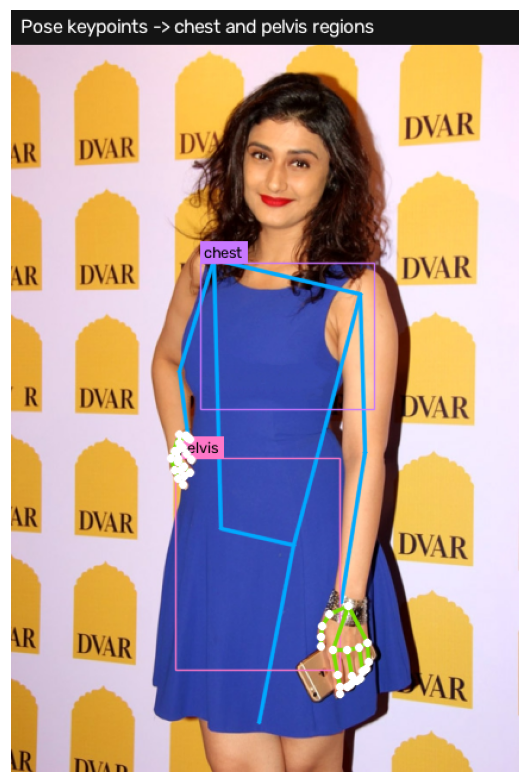

,region,x1,y1,x2,y2,torso_px
0,chest,160,213,305,334,221
1,pelvis,139,377,275,553,221


In [3]:
pipe = PrivacyPipeline(PrivacyConfig())
img = load("phone_06.jpg")
r = pipe.process(img.copy())
vis = overlay(img, r)
show(label_strip(vis, "Pose keypoints -> chest and pelvis regions"), width=6, save="stage_pose.png")
p = r.people[0]
pd.DataFrame([{"region": k, "x1": round(b.x1), "y1": round(b.y1), "x2": round(b.x2), "y2": round(b.y2)}
              for k, b in p.regions().items()]).assign(torso_px=round(p.torso_len))

## 3. Body privacy: body-part detector and pose gating

NudeNet detects 18 body-part classes, both *exposed* and *covered*. Only the exposed intimate classes are sensitive in the default profile. Two vetoes remove the detector's typical false positives: a detection lying mostly on a tracked **hand** is rejected (it confuses fingers with genitalia), and on an upright person a pelvis-class part **above the shoulders** or a chest-class part above the nose is anatomically impossible. On a fully clothed person the detector fires on covered classes, and the pipeline correctly masks nothing:

In [4]:
parts = pipe.body.detect_parts(img, list(r.people))
regions = p.regions()
chosen = {id(d) for d, _ in pipe.body.select(parts, list(r.people))}
rows = []
for d in sorted(parts, key=lambda d: -d.score):
    key = PART_REGION.get(d.label)
    inside = bool(key and regions[key].contains(*d.center))
    rows.append({"class": d.label, "score": round(d.score, 2), "expected region": key or "-",
                 "inside region": inside, "sensitive class": d.label in pipe.cfg.sensitive_parts,
                 "masked": id(d) in chosen})
pd.DataFrame(rows)

,class,score,expected region,inside region,sensitive class,masked
0,FACE_FEMALE,0.88,-,False,False,False
1,FACE_FEMALE,0.75,-,False,False,False
2,FEMALE_BREAST_COVERED,0.65,-,False,False,False
3,FEMALE_BREAST_COVERED,0.65,-,False,False,False
4,FEMALE_BREAST_COVERED,0.44,-,False,False,False
5,FEMALE_BREAST_COVERED,0.42,-,False,False,False
6,FEMALE_BREAST_COVERED,0.35,-,False,False,False
7,ARMPITS_EXPOSED,0.31,-,False,False,False
8,ARMPITS_EXPOSED,0.31,-,False,False,False
9,BELLY_COVERED,0.25,-,False,False,False


To show **where** the masks go without using any explicit imagery, the next cell temporarily treats the *covered* chest / pelvis classes as sensitive (this is what the stricter **hostel** profile does for underwear). Left: what the models see. Right: the only output that leaves the camera.

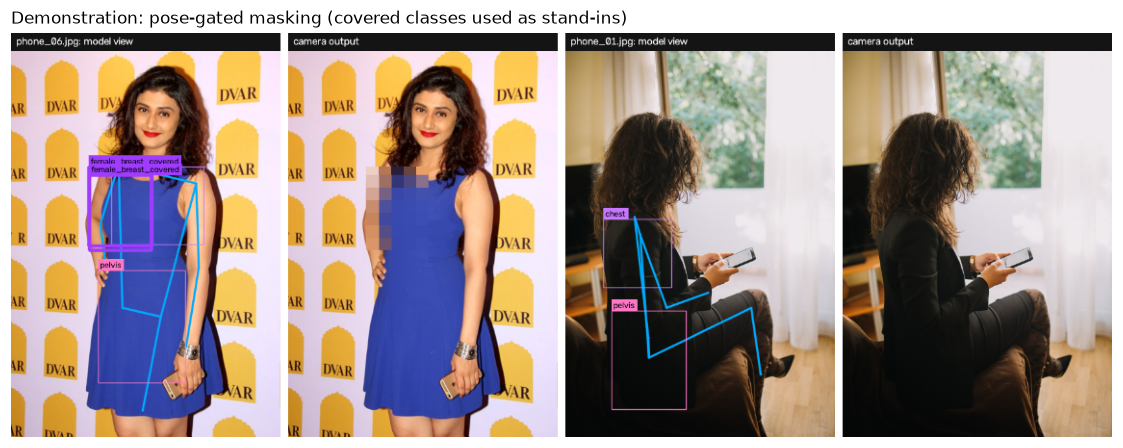

In [5]:
demo_cfg = PrivacyConfig(pin_privacy=False,
                         sensitive_parts=("FEMALE_BREAST_COVERED", "BUTTOCKS_COVERED", "FEMALE_GENITALIA_COVERED"))
demo = PrivacyPipeline(demo_cfg)
tiles = []
for name in ["phone_06.jpg", "phone_01.jpg"]:
    im = load(name); demo.reset()
    rr = demo.process(im.copy())
    tiles += [label_strip(overlay(im, rr), f"{name}: model view"), label_strip(rr.frame, "camera output")]
show(side_by_side(*tiles, height=420), "Demonstration: pose-gated masking (covered classes used as stand-ins)",
     save="stage_body_mask_demo.png")

## 4. PIN guard: device detection and hand tracking

EfficientDet-Lite0 finds phones; the COCO *cell phone* class also fires on POS handsets and PIN pads. The hand model gives 21 keypoints per hand. A hand is treated as **entering a PIN** when a fingertip (index, middle or thumb) lands on the face of a device. Pointing with an extended index finger and tapping raise the confidence.

Hands and phones at a counter are small in a CCTV frame, so three **zoom passes** look again at full model resolution, each guided by what was already found: device → crop for the hand, pose wrist → crop for the hand, hand → crop for the device. A device held against a head (pose head or detected face) is a **phone call**, not PIN entry, and is ignored.

Mask = union of hand box and device box, expanded by 25 %, **filled solid** (a pixelated finger over a keypad can still reveal which row is pressed).

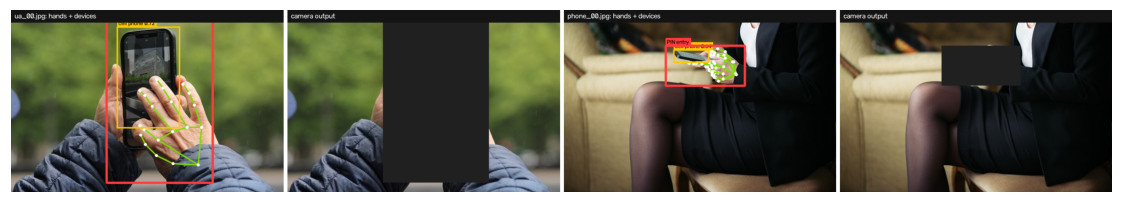

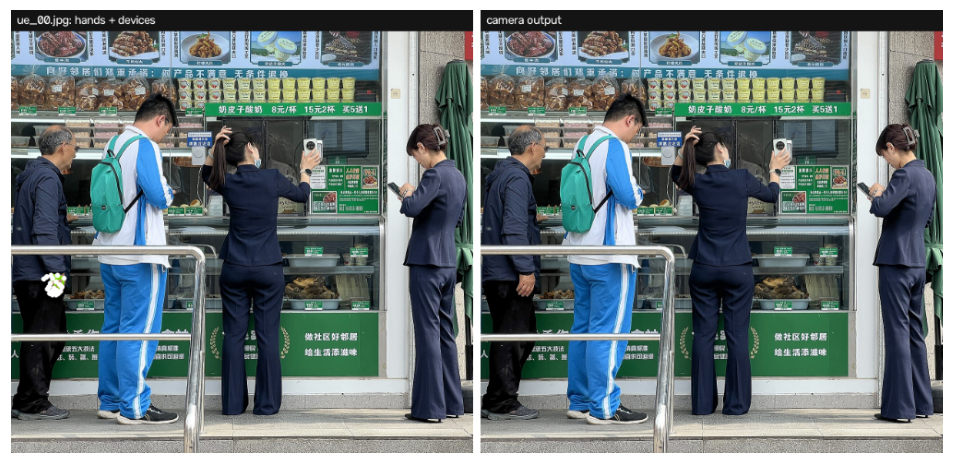

,image,hand,device,device score,confidence,evidence
0,ua_00.jpg,Right,cell phone,0.72,0.6,fingertip_on_device
1,phone_00.jpg,Left,cell phone,0.64,0.8,"fingertip_on_device, thumb_on_held_phone"


In [6]:
pin_pipe = PrivacyPipeline(PrivacyConfig(body_privacy=False))
tiles, rows = [], []
for name in ["ua_00.jpg", "phone_00.jpg", "ue_00.jpg"]:
    im = load(name); pin_pipe.reset()
    rr = pin_pipe.process(im.copy())
    tiles += [label_strip(overlay(im, rr), f"{name}: hands + devices"), label_strip(rr.frame, "camera output")]
    for it in rr.interactions:
        rows.append({"image": name, "hand": it.hand.handedness, "device": it.device.label,
                     "device score": round(it.device.score, 2), "confidence": round(it.confidence, 2),
                     "evidence": ", ".join(it.reasons)})
show(side_by_side(*tiles[:4], height=380), save="stage_pin_a.png")
show(side_by_side(*tiles[4:], height=480), save="stage_pin_b.png", width=11)
pd.DataFrame(rows)

### Occlusion: the hand hides the device

While a PIN is typed the hand often covers the phone, and the object detector loses it. The guard stores the last device box relative to the wrist and carries it with the hand. Below, the device detector is forced to return nothing after the first frame and the hand moves 40 px; the mask still follows the hand.

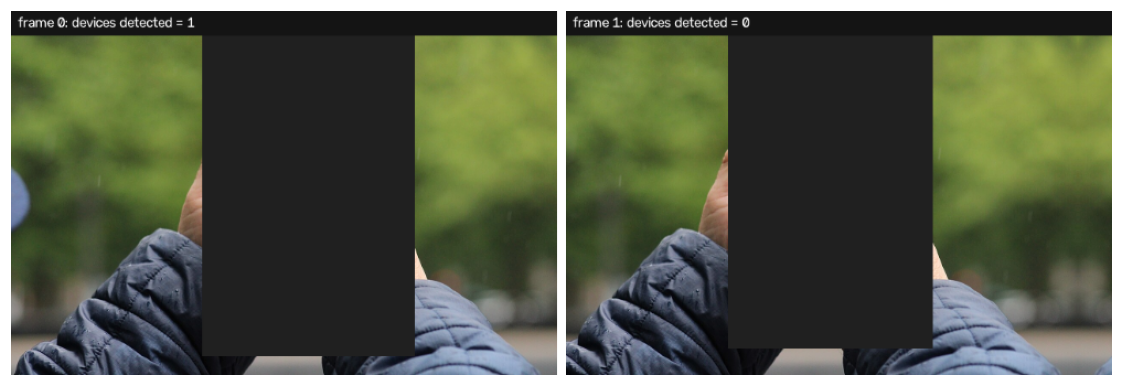

,frame,device source,evidence
0,0,devices,fingertip_on_device
1,1,device_memory,device_occluded_by_hand


In [7]:
class FirstFrameOnly:
    def __init__(self, inner): self.inner, self.n = inner, 0
    def __call__(self, *a, **k):
        self.n += 1
        return self.inner(*a, **k) if self.n == 1 else []
    def close(self): self.inner.close()

base = load("ua_00.jpg")
occ = PrivacyPipeline(PrivacyConfig(body_privacy=False))
occ.devices = FirstFrameOnly(occ.devices)
M = np.float32([[1, 0, -40], [0, 1, 0]])
seq = [base, cv2.warpAffine(base, M, (base.shape[1], base.shape[0]), borderMode=cv2.BORDER_REFLECT)]
rows, outs = [], []
for i, f in enumerate(seq):
    rr = occ.process(f.copy())
    outs.append(label_strip(rr.frame, f"frame {i}: devices detected = {len(rr.devices)}"))
    rows += [{"frame": i, "device source": it.device.source, "evidence": ", ".join(it.reasons)} for it in rr.interactions]
show(side_by_side(*outs, height=330), save="stage_occlusion.png")
pd.DataFrame(rows)

## 5. Masking is permanent

The mask is applied to the frame buffer in place, before encoding, so no unmasked copy exists. Gaussian blur is deliberately **not** used: a known blur kernel can be partly inverted by deconvolution. Pixelation keeps only a few averaged cells; solid fill keeps nothing.

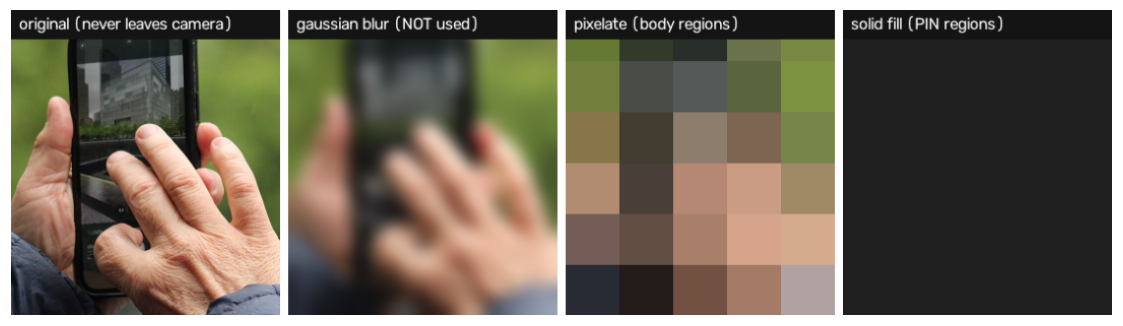

,method,distinct colours left,reversible
0,original (never leaves camera),49500,-
1,gaussian blur (NOT used),36661,partly (deconvolution)
2,pixelate (body regions),30,no
3,solid fill (PIN regions),1,no


In [8]:
from privacy_cctv.masking import apply_masks
im = load("ua_00.jpg")
box = Box(200, 40, 470, 345)
x1, y1, x2, y2 = box.as_int()
styles = {"original (never leaves camera)": None, "gaussian blur (NOT used)": "blur",
          "pixelate (body regions)": "pixelate", "solid fill (PIN regions)": "solid"}
tiles, rows = [], []
for title, style in styles.items():
    f = im.copy()
    if style == "blur":
        f[y1:y2, x1:x2] = cv2.GaussianBlur(f[y1:y2, x1:x2], (31, 31), 8)
    elif style:
        apply_masks(f, [box], cells=6, style=style)
    crop = f[y1:y2, x1:x2]
    rows.append({"method": title, "distinct colours left": len(np.unique(crop.reshape(-1, 3), axis=0)),
                 "reversible": "-" if style is None else ("partly (deconvolution)" if style == "blur" else "no")})
    tiles.append(label_strip(crop, title))
show(side_by_side(*tiles, height=300), save="masking_styles.png")
pd.DataFrame(rows)

## 6. Fail-closed

If any model raises (corrupt frame, NPU fault, out of memory) the frame is **withheld**, never passed through unmasked.

fault: RuntimeError: simulated NPU fault | max pixel value in output: 0


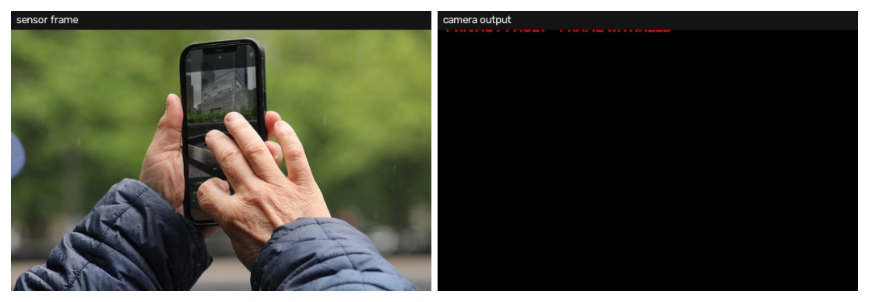

In [9]:
class BrokenModel:
    def __call__(self, *a, **k): raise RuntimeError("simulated NPU fault")
    def close(self): pass

faulty = PrivacyPipeline(PrivacyConfig(body_privacy=False))
faulty.hands = BrokenModel()
im = load("ua_00.jpg")
rr = faulty.process(im.copy())
print("fault:", rr.fault, "| max pixel value in output:", int(rr.frame[40:].max()))
show(side_by_side(label_strip(im, "sensor frame"), label_strip(rr.frame, "camera output")), width=10,
     save="failclosed.png")

## 7. Evaluation on the labelled set

Every image is processed independently with the full pipeline (default profile: body privacy + PIN guard).

* **Protected:** a sensitive region counts as protected if at least 90 % of its pixels are masked.
* **False alarm:** an image from set B or C with *anything* masked.
* **Over-mask:** masked pixels outside every sensitive region, as a share of the frame.

In [10]:
full = PrivacyPipeline(PrivacyConfig())
scores, outputs = [], {}
for name, lab in images.items():
    im = load(name); full.reset()
    rr = full.process(im.copy())
    truth = [Box(*b) for b in lab.get("sensitive", [])]
    ignore = [Box(*b) for b in lab.get("ignore", [])]
    s = score_image(name, im.shape, list(rr.regions), truth, ignore)
    scores.append({**s.__dict__, "set": lab["set"], "ms": rr.timings_ms["total"]})
    outputs[name] = (im, rr)
df = pd.DataFrame(scores)

def summarise(d):
    a, bc = d[d.set == "A"], d[d.set != "A"]
    return pd.DataFrame([
        {"metric": "Set A: sensitive regions protected (>=90% masked)", "value": f"{a.protected.sum()}/{a.gt_regions.sum()}"},
        {"metric": "Set A: mean coverage of sensitive regions", "value": f"{a.mean_coverage.mean():.1%}"},
        {"metric": "Set A: over-mask (share of frame outside truth)", "value": f"{a.over_mask_frac.mean():.1%}"},
        {"metric": "Set B: false alarms (device, no PIN entry)", "value": f"{d[d.set=='B'].false_alarm.sum()}/{(d.set=='B').sum()}"},
        {"metric": "Set C: false alarms (clothed people)", "value": f"{d[d.set=='C'].false_alarm.sum()}/{(d.set=='C').sum()}"},
        {"metric": "Sets B+C: mean share of frame masked", "value": f"{bc.masked_frac.mean():.2%}"},
    ])

summary = summarise(df)
RESULTS["eval"] = {r.metric: r.value for r in summary.itertuples()}
summary

,metric,value
0,Set A: sensitive regions protected (>=90% masked),4/8
1,Set A: mean coverage of sensitive regions,58.1%
2,Set A: over-mask (share of frame outside truth),3.6%
3,"Set B: false alarms (device, no PIN entry)",1/26
4,Set C: false alarms (clothed people),0/21
5,Sets B+C: mean share of frame masked,0.04%


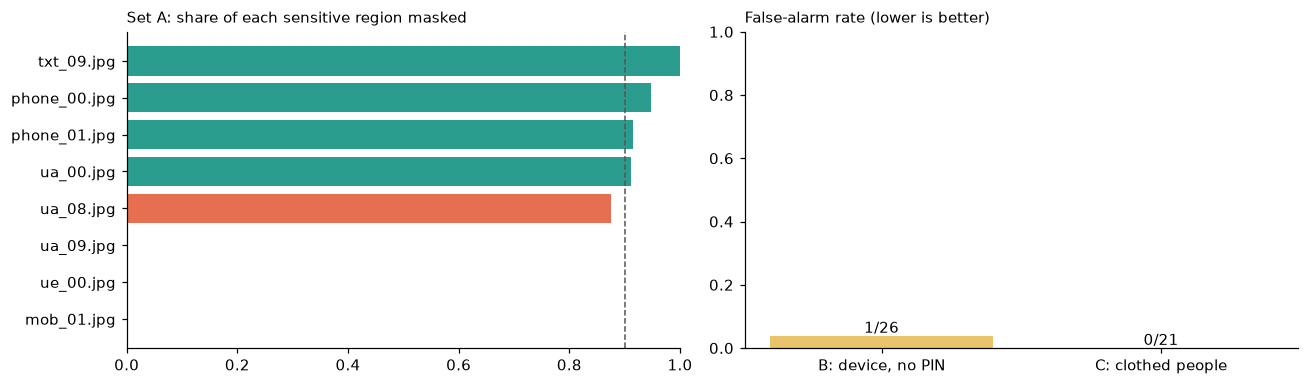

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
a = df[df.set == "A"].sort_values("mean_coverage")
axes[0].barh(a.name, a.mean_coverage, color=["#2a9d8f" if c >= 0.9 else "#e76f51" for c in a.mean_coverage])
axes[0].axvline(0.9, ls="--", c="#555", lw=1); axes[0].set_xlim(0, 1)
axes[0].set_title("Set A: share of each sensitive region masked", loc="left", fontsize=10)
fa = df.groupby("set").agg(images=("name", "size"), alarms=("false_alarm", "sum"))
fa = fa.loc[["B", "C"]]
axes[1].bar(["B: device, no PIN", "C: clothed people"], fa.alarms / fa.images, color="#e9c46a")
for i, (n, k) in enumerate(zip(fa.images, fa.alarms)):
    axes[1].text(i, k / n + 0.01, f"{k}/{n}", ha="center")
axes[1].set_ylim(0, 1); axes[1].set_title("False-alarm rate (lower is better)", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "eval_bars.png", dpi=160, bbox_inches="tight"); plt.show()

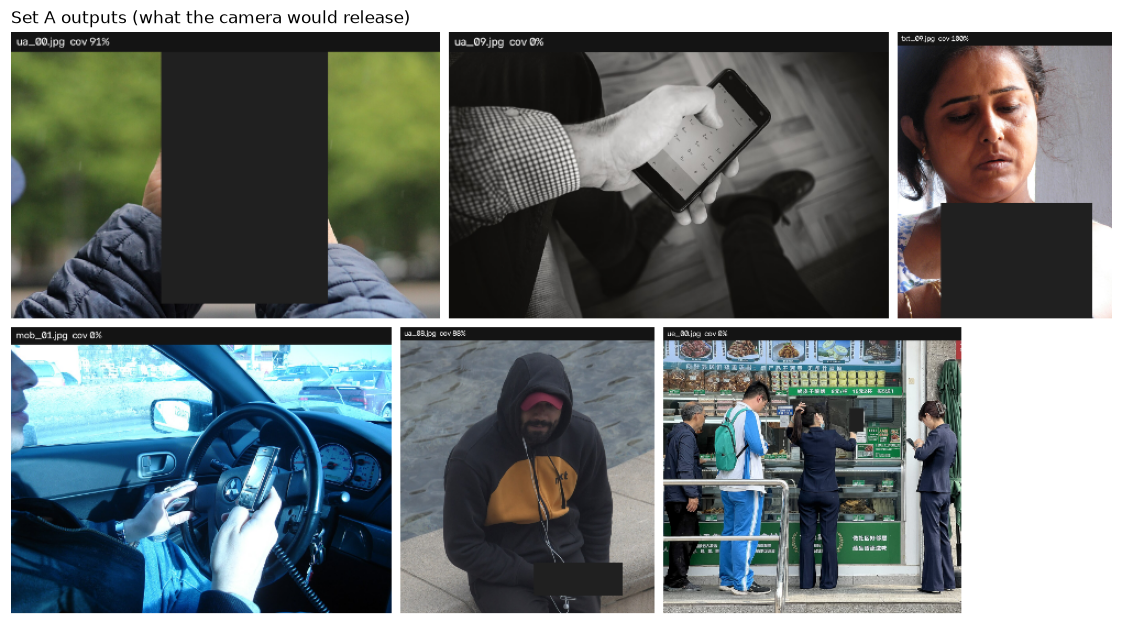

In [12]:
tiles = [label_strip(outputs[n][1].frame, f"{n}  cov {df.set_index('name').mean_coverage[n]:.0%}")
         for n in ["ua_00.jpg", "ua_09.jpg", "txt_09.jpg", "mob_01.jpg", "ua_08.jpg", "ue_00.jpg"]]
row1, row2 = side_by_side(*tiles[:3], height=260), side_by_side(*tiles[3:], height=260)
w = max(row1.shape[1], row2.shape[1])
pad = lambda x: cv2.copyMakeBorder(x, 0, 8, 0, w - x.shape[1], cv2.BORDER_CONSTANT, value=(255, 255, 255))
show(np.vstack([pad(row1), pad(row2)]), "Set A outputs (what the camera would release)", save="eval_gallery.png")

### Failures and false alarms

Listing the cases that went wrong is part of the result.

,name,set,mean_coverage,masked_frac,false_alarm
2,mob_01.jpg,A,0.000,0.000,False
5,ua_08.jpg,A,0.875,0.040,False
6,ua_09.jpg,A,0.000,0.000,False
7,ue_00.jpg,A,0.000,0.001,False
29,ue_01.jpg,B,NaN,0.020,True


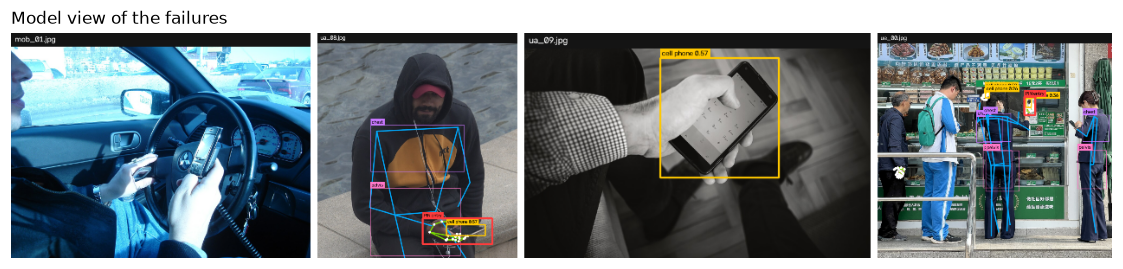

In [13]:
bad = df[((df.set == "A") & (df.mean_coverage < 0.9)) | df.false_alarm]
cols = ["name", "set", "mean_coverage", "masked_frac", "false_alarm"]
display(bad[cols].round(3))
names = list(bad.name)[:4]
if names:
    show(side_by_side(*[label_strip(overlay(*outputs[n][:1], outputs[n][1]), n) for n in names], height=260),
         "Model view of the failures", save="eval_failures.png")

### Profile trade-off: hostel mode on clothed people

The hostel profile also masks *covered* buttocks / genitalia (underwear in corridors). That costs false alarms on ordinary clothed people, which is why it is a per-site choice rather than the default.

In [14]:
rows = []
for prof in ["retail", "hostel"]:
    pp = PrivacyPipeline(PROFILES[prof])
    c_names = [n for n, l in images.items() if l["set"] == "C"]
    alarms, area = 0, []
    for n in c_names:
        im = load(n); pp.reset()
        rr = pp.process(im.copy())
        s = score_image(n, im.shape, list(rr.regions), [])
        alarms += s.false_alarm; area.append(s.masked_frac)
    rows.append({"profile": prof, "set C images": len(c_names), "false alarms": alarms,
                 "mean share of frame masked": f"{np.mean(area):.2%}"})
    pp.close()
RESULTS["profiles"] = rows
pd.DataFrame(rows)

,profile,set C images,false alarms,mean share of frame masked
0,retail,21,0,0.00%
1,hostel,21,0,0.00%


### Policy trade-off: interaction-gated vs. mask every device

The default policy masks a device only while a hand is operating it. The stricter **bank** policy masks every detected payment device all the time (sensible for an ATM or PIN-pad zone). It recovers PIN entries where the hand was never detected, but it also masks idle devices. The middle row is an ablation with the zoom passes switched off.

In [15]:
rows = []
for label, cfg in [("interaction-gated (default)", PrivacyConfig()),
                   ("default without zoom passes", PrivacyConfig(zoom_crops=0)),
                   ("mask every device (bank)", PrivacyConfig(mask_all_devices=True))]:
    pp = PrivacyPipeline(cfg)
    res = {"A": [], "B": []}
    for n, l in images.items():
        if l["set"] not in res: continue
        im = load(n); pp.reset()
        rr = pp.process(im.copy())
        res[l["set"]].append(score_image(n, im.shape, list(rr.regions), [Box(*b) for b in l.get("sensitive", [])],
                                         [Box(*b) for b in l.get("ignore", [])]))
    pp.close()
    rows.append({"policy": label,
                 "Set A protected": f"{sum(s.protected for s in res['A'])}/{len(res['A'])}",
                 "Set A mean coverage": f"{np.mean([s.mean_coverage for s in res['A']]):.1%}",
                 "Set B false alarms": f"{sum(s.false_alarm for s in res['B'])}/{len(res['B'])}"})
RESULTS["policies"] = rows
pd.DataFrame(rows)

,policy,Set A protected,Set A mean coverage,Set B false alarms
0,interaction-gated (default),4/8,58.1%,1/26
1,default without zoom passes,4/8,47.2%,0/26
2,mask every device (bank),5/8,70.6%,16/26


## 8. Temporal hold: why masks are released late

A detector that finds the PIN pad in 80 % of frames still leaves 1 frame in 5 unmasked, which is enough to read a digit. The pipeline masks **immediately** and releases only after `hold_frames` frames without evidence. The simulation below feeds 20 000 frames of continuous PIN entry through that rule for different per-frame detection rates, with misses that are random (top) or in bursts (bottom, a hand covering the device for several frames).

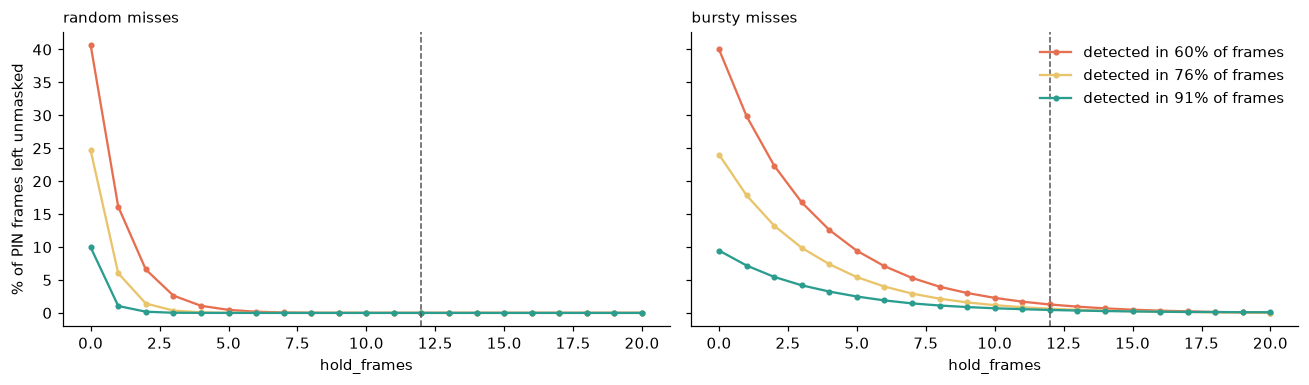

,misses,detection rate,"leak, no hold","leak, hold=12"
0,random misses,59%,40.7%,0.01%
1,bursty misses,60%,40.0%,1.28%
2,random misses,75%,24.7%,0.00%
3,bursty misses,76%,24.0%,0.63%
4,random misses,90%,10.0%,0.00%
5,bursty misses,91%,9.5%,0.45%


In [16]:
rng = np.random.default_rng(7)
holds = np.arange(0, 21)
def bursty(p, n, mean_burst=4):
    out, miss = np.ones(n, bool), False
    for i in range(n):
        miss = rng.random() < (1 - 1 / mean_burst if miss else (1 - p) / (p * mean_burst))
        out[i] = not miss
    return out

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
hold_rows = []
for p, col in zip([0.6, 0.75, 0.9], ["#e76f51", "#e9c46a", "#2a9d8f"]):
    for ax, kind in zip(axes, ["random misses", "bursty misses"]):
        det = rng.random(20000) < p if kind == "random misses" else bursty(p, 20000)
        leaks = [leak_rate(det, h) * 100 for h in holds]
        ax.plot(holds, leaks, marker="o", ms=3, color=col, label=f"detected in {det.mean():.0%} of frames")
        hold_rows.append({"misses": kind, "detection rate": f"{det.mean():.0%}",
                          "leak, no hold": f"{leaks[0]:.1f}%", "leak, hold=12": f"{leaks[12]:.2f}%"})
for ax, kind in zip(axes, ["random misses", "bursty misses"]):
    ax.axvline(12, ls="--", c="#555", lw=1); ax.set_xlabel("hold_frames"); ax.set_title(kind, loc="left", fontsize=10)
axes[0].set_ylabel("% of PIN frames left unmasked"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "hold_curve.png", dpi=160, bbox_inches="tight"); plt.show()
RESULTS["hold"] = hold_rows
pd.DataFrame(hold_rows)

## 9. Speed

The camera runs on a continuous stream, so the pose and hand models run in **video mode** (they track between frames instead of searching from scratch). To get a continuous 640×480 stream without filming anyone, a camera *pan* is simulated by sliding a window across a high-resolution photo of a busy shop counter (several people, hands and phones), which is close to the worst case. Timings are wall-clock on this laptop's CPU (no GPU, no NPU).

The live configuration runs the three independent branches (pose → body parts, device detector, hand tracker) **in parallel threads** and allows **one zoom crop per pass per frame**. The table compares it with running everything serially and with the zoom passes off.

In [17]:
big = load("ue_00.jpg", max_side=1100)
H, W = big.shape[:2]
frames = []
for i in range(180):
    t = i / 179
    x = int((W - 640) * (0.5 - 0.5 * np.cos(np.pi * 2 * t)))
    y = int((H - 480) * 0.35)
    frames.append(big[y:y + 480, x:x + 640].copy())

def bench(cfg):
    pp = PrivacyPipeline(cfg)
    for f in frames[:10]: pp.process(f.copy(), None)  # warm-up
    pp.reset()
    out = [pp.process(f.copy(), int(i * 33.3)).timings_ms for i, f in enumerate(frames)]
    pp.close()
    return pd.DataFrame(out).fillna(0)

configs = {"serial, 1 zoom crop": PrivacyConfig(video_mode=True, zoom_crops=1, parallel=False),
           "parallel, 1 zoom crop (live)": PrivacyConfig(video_mode=True, zoom_crops=1),
           "parallel, zoom off": PrivacyConfig(video_mode=True, zoom_crops=0)}
runs = {name: bench(cfg) for name, cfg in configs.items()}
abl = pd.DataFrame([{"configuration": n, **{k: round(v, 1) for k, v in latency_summary(list(d["total"])).items()}}
                    for n, d in runs.items()])
t = runs["parallel, 1 zoom crop (live)"]
stages = ["prep", "pose", "body_parts", "devices", "hands", "hands_roi", "devices_roi", "fuse", "mask"]
lat = latency_summary(list(t["total"]))
stage_tbl = pd.DataFrame({"mean ms": t[stages].mean().round(1), "p95 ms": t[stages].quantile(0.95).round(1)})
RESULTS["latency"] = {**{k: round(v, 1) for k, v in lat.items()}, "stages": stage_tbl["mean ms"].to_dict(),
                      "ablation": abl.to_dict("records")}
display(stage_tbl.T)
abl

,prep,pose,body_parts,devices,hands,hands_roi,devices_roi,fuse,mask
mean ms,1.3,41.7,44.6,55.1,57.7,3.9,46.4,0.4,0.1
p95 ms,2.0,50.9,49.6,65.0,76.3,25.8,57.1,0.7,0.1


,configuration,mean_ms,p50_ms,p95_ms,fps
0,"serial, 1 zoom crop",197.5,200.7,221.0,5.1
1,"parallel, 1 zoom crop (live)",139.1,142.6,159.9,7.2
2,"parallel, zoom off",95.5,98.3,105.3,10.5


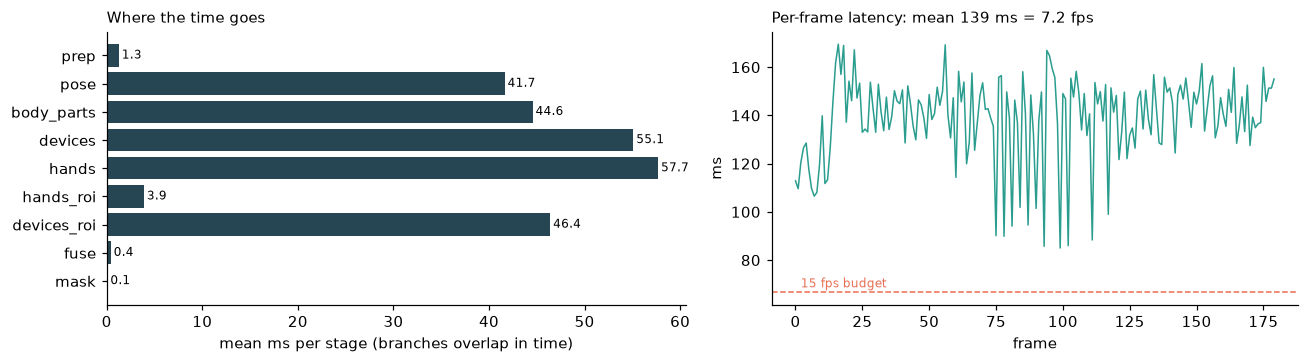

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.1, 1]})
m = t[stages].mean()
axes[0].barh(m.index[::-1], m.values[::-1], color="#264653")
for i, v in enumerate(m.values[::-1]): axes[0].text(v + 0.3, i, f"{v:.1f}", va="center", fontsize=8)
axes[0].set_xlabel("mean ms per stage (branches overlap in time)"); axes[0].set_title("Where the time goes", loc="left", fontsize=10)
axes[1].plot(t["total"].values, lw=1, color="#2a9d8f")
axes[1].axhline(1000 / 15, ls="--", c="#e76f51", lw=1); axes[1].text(2, 1000 / 15 + 2, "15 fps budget", color="#e76f51", fontsize=8)
axes[1].set_xlabel("frame"); axes[1].set_ylabel("ms"); axes[1].set_title(f"Per-frame latency: mean {lat['mean_ms']:.0f} ms = {lat['fps']:.1f} fps", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "latency.png", dpi=160, bbox_inches="tight"); plt.show()

## 10. Live webcam prototype

The same pipeline runs on the laptop webcam. The window and the optional recording only ever contain masked frames:

```
python app/run_camera.py --source 0 --profile retail --record data/runs/demo.mp4 --log data/runs/demo.csv
```

Press **g** while you are actually typing a PIN to mark ground truth; the per-frame log then gives frame-level recall, false-mask rate and FPS for your own recording. The cell below analyses the newest log if one exists.

In [19]:
logs = sorted((ROOT / "data" / "runs").glob("*.csv"))
if not logs:
    print("No webcam log yet. Run app/run_camera.py with --log to record one.")
else:
    log = pd.read_csv(logs[-1])
    gt, pred = log.ground_truth_pin == 1, log.pin_active == 1
    print(f"{logs[-1].name}: {len(log)} frames")
    print(f"PIN frames masked  : {(gt & pred).sum()}/{gt.sum()}  ({(gt & pred).sum() / max(gt.sum(), 1):.1%})")
    print(f"non-PIN frames masked: {(~gt & pred).sum()}/{(~gt).sum()}")
    print(f"mean latency: {log.total.mean():.1f} ms ({1000 / log.total.mean():.1f} fps)")

No webcam log yet. Run app/run_camera.py with --log to record one.


## 11. Summary

In [20]:
(ROOT / "docs" / "results.json").write_text(json.dumps(RESULTS, indent=2, default=str))
lat = RESULTS["latency"]
print("Evaluation")
for k, v in RESULTS["eval"].items(): print(f"  {k:<55} {v}")
print(f"\nSpeed (640x480, laptop CPU): {lat['mean_ms']} ms mean, {lat['p95_ms']} ms p95 -> {lat['fps']} fps")

Evaluation
  Set A: sensitive regions protected (>=90% masked)       4/8
  Set A: mean coverage of sensitive regions               58.1%
  Set A: over-mask (share of frame outside truth)         3.6%
  Set B: false alarms (device, no PIN entry)              1/26
  Set C: false alarms (clothed people)                    0/21
  Sets B+C: mean share of frame masked                    0.04%

Speed (640x480, laptop CPU): 139.1 ms mean, 159.9 ms p95 -> 7.2 fps
